In [1200]:
#PHASE 1 — Data understanding and exploration
#Task 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
sns.set_theme(style="whitegrid")

In [1201]:
#Task 2. Load the dataset
#Purpose: Load the hospital readmission dataset into Python.
df = pd.read_csv(
    "../data/diabetic_data.csv",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (101766, 50)


In [1202]:
#Task 3 — Inspect rows, columns and data types
#Purpose: Understand the structure of the dataset.
# Display first five rows
display(df.head())

# Display dataset information
df.info()

# Display statistical summary
display(df.describe(include="all"))

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,1.017660e+05,1.017660e+05,99493,101766,101766,3197,101766.000000,101766.000000,101766.000000,101766.000000,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,NaN,NaN,5,3,10,9,NaN,NaN,NaN,NaN,...,1,4,4,2,2,2,2,2,2,3
top,NaN,NaN,Caucasian,Female,[70-80),[75-100),NaN,NaN,NaN,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
freq,NaN,NaN,76099,54708,26068,1336,NaN,NaN,NaN,NaN,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864
mean,1.652016e+08,5.433040e+07,NaN,NaN,NaN,NaN,2.024006,3.715642,5.754437,4.395987,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.026403e+08,3.869636e+07,NaN,NaN,NaN,NaN,1.445403,5.280166,4.064081,2.985108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.252200e+04,1.350000e+02,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,8.496119e+07,2.341322e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.523890e+08,4.550514e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,7.000000,4.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2.302709e+08,8.754595e+07,NaN,NaN,NaN,NaN,3.000000,4.000000,7.000000,6.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [1203]:
#Task 4 — Analyse missing values
#Purpose: Identify columns with missing data and understand how much information is missing.
# Calculate missing-value percentages
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Display columns with missing values
missing_percentage = missing_percentage[missing_percentage > 0]

print(missing_percentage.sort_values(ascending=False))

weight               96.858479
max_glu_serum        94.746772
A1Cresult            83.277322
medical_specialty    49.082208
payer_code           39.557416
race                  2.233555
diag_3                1.398306
diag_2                0.351787
diag_1                0.020636
dtype: float64


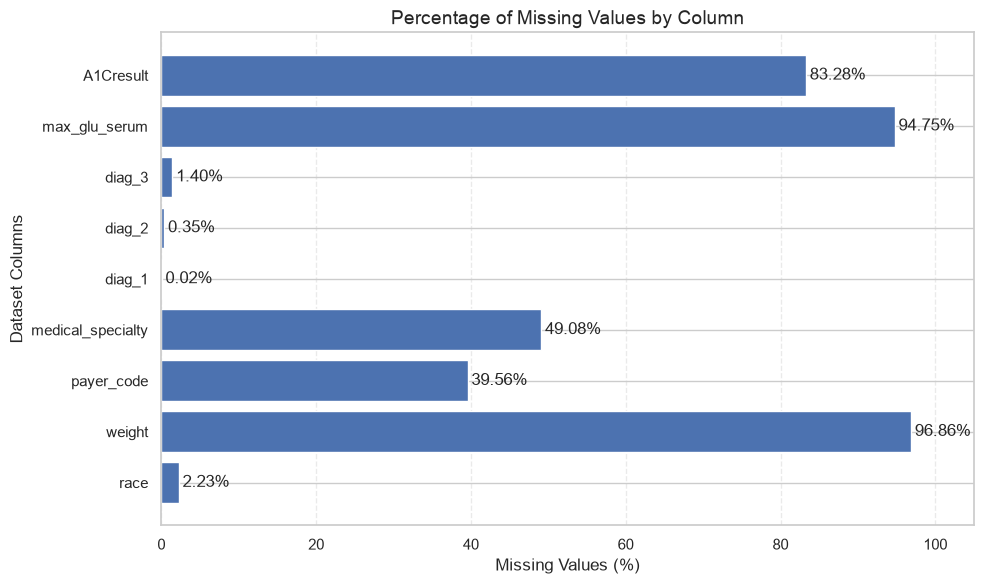

In [1204]:
#Visualise missing values:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    missing_percentage.index,
    missing_percentage.values
)

# Add percentage labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.title("Percentage of Missing Values by Column", fontsize=14)
plt.xlabel("Missing Values (%)")
plt.ylabel("Dataset Columns")

plt.xlim(0, 105)
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


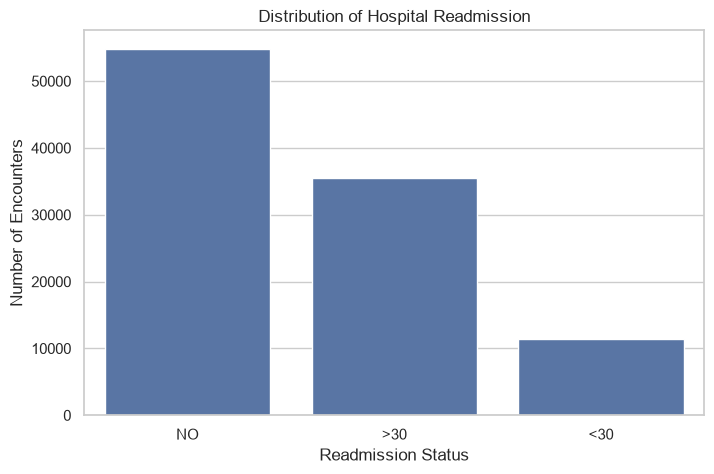

In [1205]:
#Task 5 — Analyse readmission distribution
#Purpose: Understand how many patients were readmitted and how many were not.
readmission_counts = df["readmitted"].value_counts()

print(readmission_counts)

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="readmitted", order=["NO", ">30", "<30"])

plt.title("Distribution of Hospital Readmission")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Encounters")

plt.show()

In [1206]:
#Task 6 — Create binary target
# Create binary target variable
df["target"] = (df["readmitted"] == "<30").astype(int)

# Verify target column
print(df[["readmitted", "target"]].head())

print("\nTarget distribution:")
print(df["target"].value_counts())

  readmitted  target
0         NO       0
1        >30       0
2         NO       0
3         NO       0
4         NO       0

Target distribution:
target
0    90409
1    11357
Name: count, dtype: int64


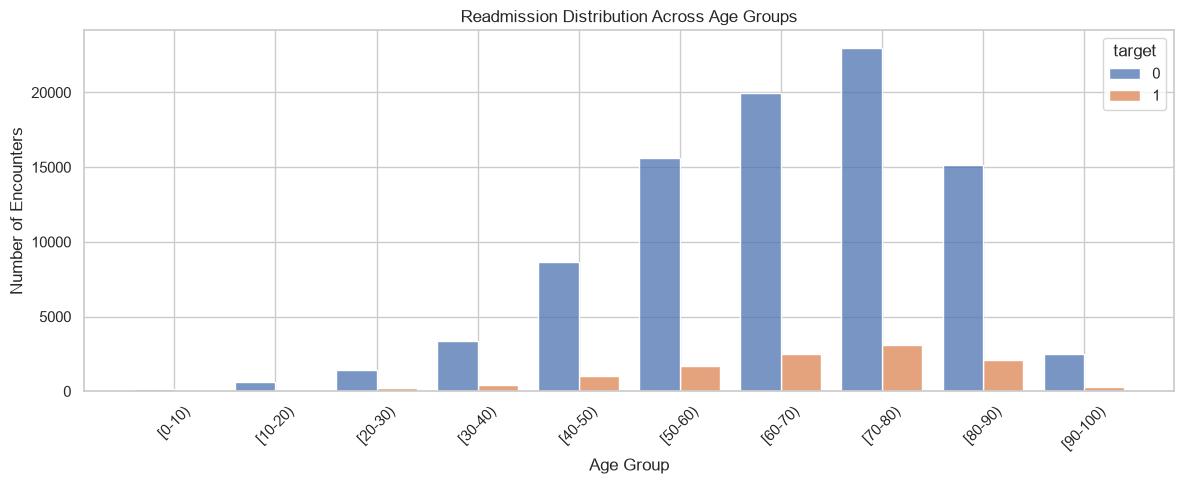

In [1207]:
# Task 7 - Explore age and gender

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="age",
    hue="target",
    multiple="dodge",
    shrink=0.8
)

plt.title("Readmission Distribution Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

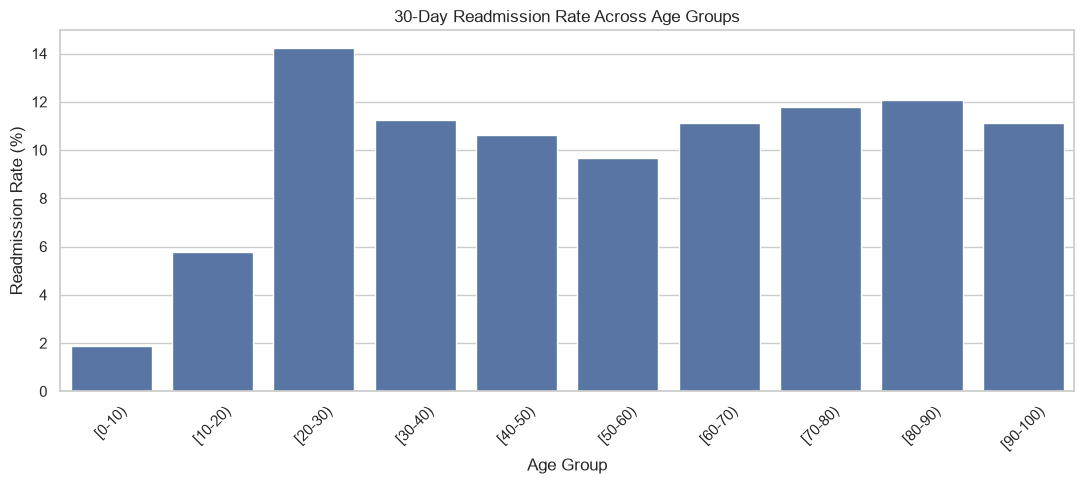

In [1208]:
# age analysis
age_readmission_rate = df.groupby("age")["target"].mean() * 100

plt.figure(figsize=(11, 5))

sns.barplot(
    x=age_readmission_rate.index,
    y=age_readmission_rate.values
)

plt.title("30-Day Readmission Rate Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

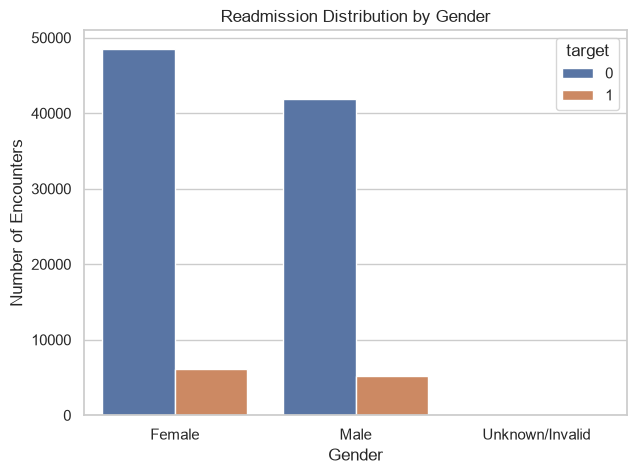

In [1209]:
#Gender analysis:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="gender", hue="target")

plt.title("Readmission Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Encounters")

plt.show()

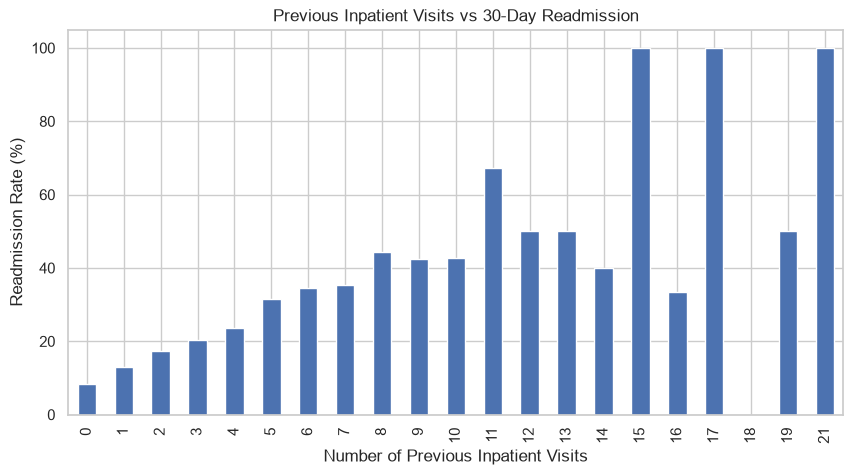

In [1210]:
#Task 8 — Explore previous hospital visits
#Purpose: Check whether patients with more previous inpatient visits have higher readmission rates.
previous_visits = df.groupby("number_inpatient")["target"].mean() * 100

plt.figure(figsize=(10, 5))

previous_visits.plot(kind="bar")

plt.title("Previous Inpatient Visits vs 30-Day Readmission")
plt.xlabel("Number of Previous Inpatient Visits")
plt.ylabel("Readmission Rate (%)")

plt.show()

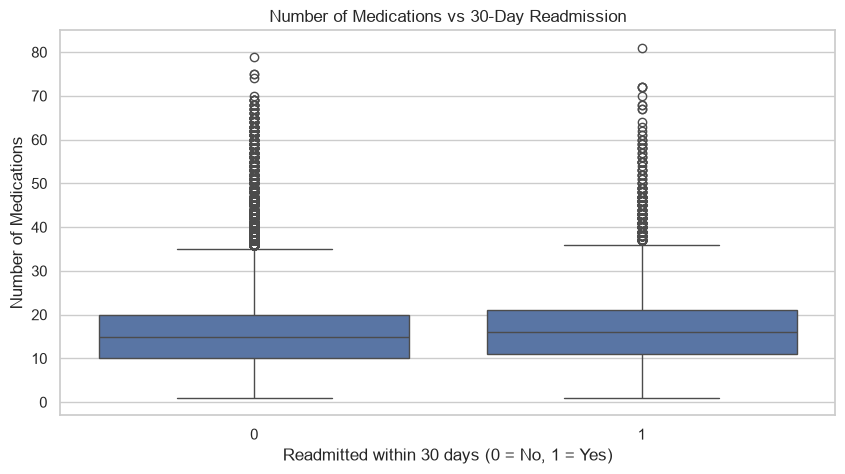

In [1211]:
#Task 9— Explore medication patterns
#Purpose: Investigate whether the number of medications prescribed differs between readmitted and non-readmitted encounters.
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="target",
    y="num_medications"
)

plt.title("Number of Medications vs 30-Day Readmission")
plt.xlabel("Readmitted within 30 days (0 = No, 1 = Yes)")
plt.ylabel("Number of Medications")

plt.show()

In [1212]:
#PHASE 2 — DATA CLEANING
#Task 10 — Handle missing values
#Purpose: Decide how to treat missing data instead of blindly deleting rows.

#create working copy:
df_clean = df.copy()

#handle the missing values:
# Drop columns with excessive missing values
df_clean = df_clean.drop(columns=["weight", "payer_code"])

# Fill missing categorical values
df_clean["max_glu_serum"] = df_clean["max_glu_serum"].fillna("Not measured")
df_clean["A1Cresult"] = df_clean["A1Cresult"].fillna("Not measured")

df_clean["medical_specialty"] = df_clean["medical_specialty"].fillna("Unknown")

df_clean["race"] = df_clean["race"].fillna("Unknown")

# Fill missing diagnosis values
diagnosis_columns = ["diag_1", "diag_2", "diag_3"]

for col in diagnosis_columns:
    df_clean[col] = df_clean[col].fillna("Unknown")

print("Missing values handled!")

Missing values handled!


In [1213]:
#Check the remaining missing values:
print(df_clean.isnull().sum().sort_values(ascending=False).head(15))

encounter_id      0
chlorpropamide    0
acetohexamide     0
glipizide         0
glyburide         0
tolbutamide       0
pioglitazone      0
rosiglitazone     0
acarbose          0
miglitol          0
troglitazone      0
tolazamide        0
examide           0
citoglipton       0
insulin           0
dtype: int64


In [1214]:
#Task 11 — Drop unnecessary columns
#Purpose: Remove identifiers and features that should not be used directly as model inputs.
print(df_clean.columns.tolist())

#For the initial modelling dataset, we should exclude:
#- encounter_id: Unique encounter identifier.
#- patient_nbr: Patient identifier.
#- readmitted: Original target category, which would leak the answer.
#Keep patient_nbr temporarily because we need it to ensure that encounters belonging to the same patient do not appear in both training and testing datasets.

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted', 'target']


In [1215]:
#Creating a separate patient ID variable:
# Preserve patient IDs for group-based train/test splitting
patient_groups = df_clean["patient_nbr"].copy()

print("Patient groups preserved:", len(patient_groups))
print("Unique patients:", patient_groups.nunique())

Patient groups preserved: 101766
Unique patients: 71518


In [1216]:
#removing the identifiers and original target from the feature table:
df_model = df_clean.drop(
    columns=["encounter_id", "patient_nbr", "readmitted"]
)

print("Model feature dataset shape:", df_model.shape)

Model feature dataset shape: (101766, 46)


In [1217]:
#Task 12 — Handle duplicate encounters
#Purpose: Check whether the same hospital encounter appears more than once.
duplicate_count = df_clean["encounter_id"].duplicated().sum()

print("Number of duplicate encounters:", duplicate_count)

Number of duplicate encounters: 0


In [1218]:
#Task 13 — Handle categorical values
# Convert categorical ID columns into strings

categorical_id_columns = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

for col in categorical_id_columns:
    df_model[col] = df_model[col].astype("str")

print("Categorical ID columns converted successfully!")

print(df_model[categorical_id_columns].dtypes)

Categorical ID columns converted successfully!
admission_type_id           str
discharge_disposition_id    str
admission_source_id         str
dtype: object


In [1219]:
# Task 14 - Handle numerical columns
#Purpose: Identify numerical features, understand their ranges and check for unusual values before model training.
#Step 1 — Identify numerical columns
numerical_columns = df_model.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nNumber of numerical columns:", len(numerical_columns))

Numerical columns:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'target']

Number of numerical columns: 9


In [1220]:
# Step 2: Statistical summary of numerical columns
#Purpose: Examine the minimum, maximum, average and spread of each numerical column to identify unusual values.
display(df_model[numerical_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0
target,101766.0,0.111599,0.314874,0.0,0.0,0.0,0.0,1.0


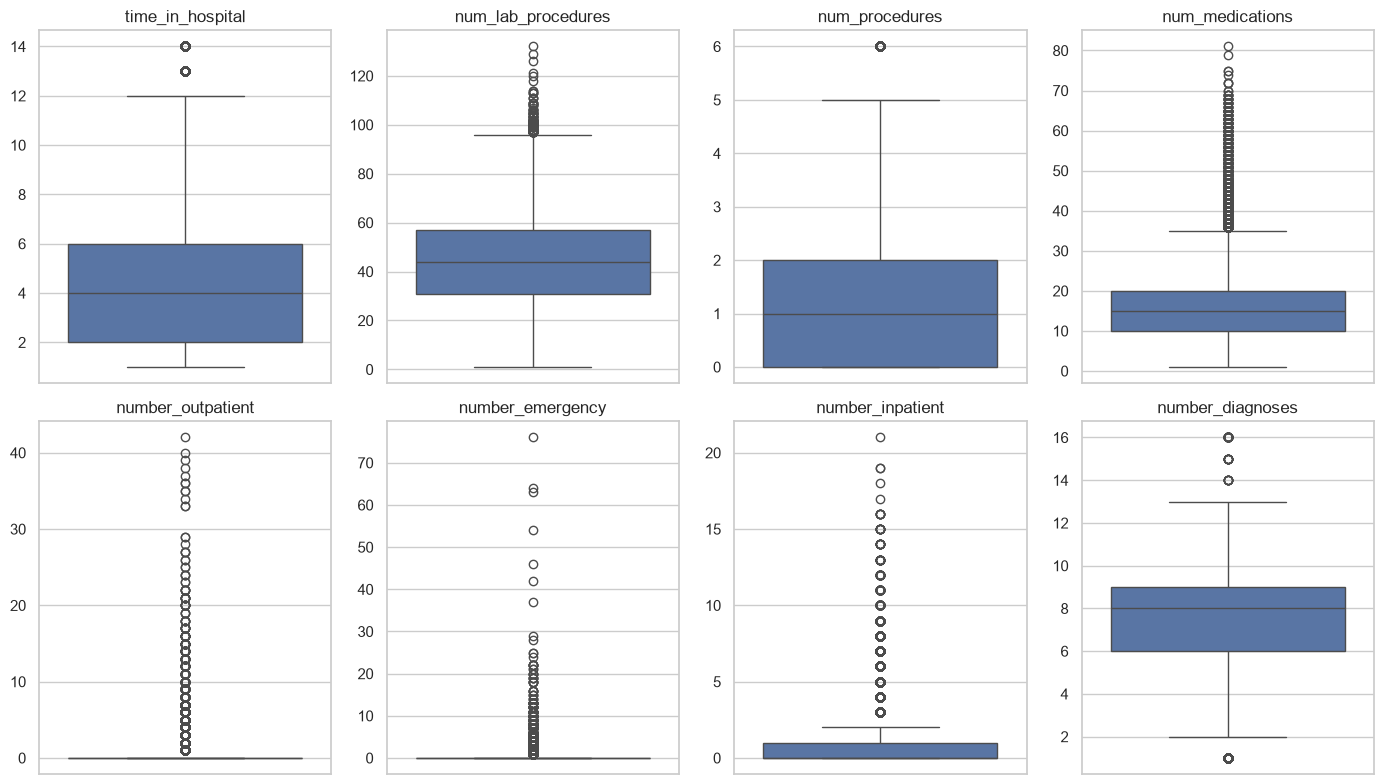

In [1221]:
#Step 3: Visualise numerical distributions
#Purpose: Use boxplots to identify unusually high values and understand the spread of numerical features.
numerical_features = [
    col for col in numerical_columns if col != "target"
]

plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_features, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df_model[col])
    plt.title(col)
    plt.ylabel("")

plt.tight_layout()
plt.show()

In [1222]:
#Checking the cleaned dataset for remaining missing values.
missing_after_cleaning = df_model.isnull().sum()

print("Total missing values:", missing_after_cleaning.sum())

print("\nColumns with missing values:")
print(missing_after_cleaning[missing_after_cleaning > 0])

Total missing values: 0

Columns with missing values:
Series([], dtype: int64)


In [1223]:
#PHASE 3 — FEATURE PREPARATION
#Task 15 — Separate features and target
#To separate the information used for prediction from the outcome we want to predict. This allows us to train our ML models correctly.
# Separate features and target

X = df_model.drop(columns=["target"])
y = df_model["target"]

# Check the results
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features (X) shape: (101766, 45)
Target (y) shape: (101766,)

Target distribution:
target
0    90409
1    11357
Name: count, dtype: int64


In [1224]:
#Task 16 — Identify categorical columns
#Purpose: Identify columns containing categories or labels that must be converted into numerical values before training the ML models.
categorical_columns = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

print("Number of categorical columns:", len(categorical_columns))

print("\nCategorical columns:")
print(categorical_columns)

Number of categorical columns: 37

Categorical columns:
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [1225]:
#Task 17 — Identify numerical columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Number of numerical columns:", len(numerical_features))

print("\nNumerical columns:")
print(numerical_features)


Number of numerical columns: 8

Numerical columns:
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [1226]:
#Task 18 – Encode categorical features
#Purpose:Convert categories into numerical representations
print("Patient groups available:", "patient_groups" in globals())

if "patient_groups" in globals():
    print("Number of rows:", len(patient_groups))
    print("Unique patients:", patient_groups.nunique())
    print("Rows in X:", len(X))

Patient groups available: True
Number of rows: 101766
Unique patients: 71518
Rows in X: 101766


In [1227]:
#Split the dataset
#Purpose: Separate training and testing data without patient overlap.
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=patient_groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (81613, 45)
Testing features: (20153, 45)

Training target distribution:
target
0    88.719934
1    11.280066
Name: proportion, dtype: float64

Testing target distribution:
target
0    89.326651
1    10.673349
Name: proportion, dtype: float64


In [1228]:
#Prepare the encoding pipeline
#Purpose: Convert categorical columns into numerical values while learning categories only from training data.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Process numerical features
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_columns)
    ]
)
#- handle_unknown="ignore" prevents errors if the test set contains a category not seen during training.

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [1229]:
#Fit the pipeline on training data
#Purpose: Learn category mappings and scaling values from training data, then apply the same transformations to test data.
# Fit on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the training-fitted pipeline
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)
print("\nPreprocessing completed successfully!")

Training data after preprocessing: (81613, 2406)
Testing data after preprocessing: (20153, 2406)

Preprocessing completed successfully!


In [1230]:
#Task 19:Task 19: Scale Numerical Features
#Step 1:  Verify preprocessing
import numpy as np
from scipy import sparse

# Extract stored values from sparse matrices
train_values = (
    X_train_processed.data
    if sparse.issparse(X_train_processed)
    else np.asarray(X_train_processed)
)

test_values = (
    X_test_processed.data
    if sparse.issparse(X_test_processed)
    else np.asarray(X_test_processed)
)

print("Training data contains NaN:", np.isnan(train_values).any())
print("Testing data contains NaN:", np.isnan(test_values).any())

print("Training data contains infinity:", np.isinf(train_values).any())
print("Testing data contains infinity:", np.isinf(test_values).any())

Training data contains NaN: False
Testing data contains NaN: False
Training data contains infinity: False
Testing data contains infinity: False


In [1231]:
# Numerical features come first in our ColumnTransformer
# Extract the first 8 columns

if sparse.issparse(X_train_processed):
    numerical_data = X_train_processed[:, :8].toarray()
else:
    numerical_data = X_train_processed[:, :8]

print("Means of scaled numerical features:")
print(np.round(numerical_data.mean(axis=0), 4))

print("\nStandard deviations of scaled numerical features:")
print(np.round(numerical_data.std(axis=0), 4))

Means of scaled numerical features:
[ 0.  0.  0.  0.  0. -0. -0.  0.]

Standard deviations of scaled numerical features:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [1232]:
#Task 28 — Save processed training/test data
#Purpose: Share the same processed training and testing data with all teammates so everyone trains and evaluates their models consistently.
import os
import joblib

# Create a folder to store shared processed data
os.makedirs("../data/processed", exist_ok=True)

# Save processed training and testing features
joblib.dump(X_train_processed, "../data/processed/X_train_processed.pkl")
joblib.dump(X_test_processed, "../data/processed/X_test_processed.pkl")

# Save training and testing target values
joblib.dump(y_train, "../data/processed/y_train.pkl")
joblib.dump(y_test, "../data/processed/y_test.pkl")

print("Processed training and testing data saved successfully!")

Processed training and testing data saved successfully!


In [1233]:
#Task 29 — Save preprocessing pipeline
#Purpose: Save the fitted preprocessing pipeline so teammates can apply the exact same transformations to new patient data.
# Save the fitted preprocessing pipeline
joblib.dump(preprocessor, "../data/processed/preprocessor.joblib")

print("Preprocessing pipeline saved successfully!")

Preprocessing pipeline saved successfully!


In [1234]:
#Task 30 — Document feature names and target
#Purpose: Give Neeraj, Deekshitha, and Swetcha a clear description of the data they should use to train their models.
# Document the feature names and target

feature_info = {
    "number_of_features": len(X.columns),
    "feature_names": X.columns.tolist(),
    "target_name": "target",
    "target_description": "1 = Readmitted within 30 days, 0 = Not readmitted within 30 days",
    "positive_class": 1,
    "negative_class": 0
}

# Save feature information for teammates
joblib.dump(feature_info, "../data/processed/feature_info.joblib")

print("Feature information saved successfully!")
print("Number of features:", feature_info["number_of_features"])
print("Target:", feature_info["target_name"])
print("Target distribution:")
print(y.value_counts())

Feature information saved successfully!
Number of features: 45
Target: target
Target distribution:
target
0    90409
1    11357
Name: count, dtype: int64


In [ ]:
#Task 31 — Upload work to GitHub
#Purpose: Make your preprocessing work available to your teammates.
import os

processed_folder = "../data/processed"

print("Saved files and their sizes:\n")

for filename in os.listdir(processed_folder):
    file_path = os.path.join(processed_folder, filename)
    size_mb = os.path.getsize(file_path) / (1024 * 1024)

    print(f"{filename}: {size_mb:.2f} MB")